<a href="https://colab.research.google.com/github/martinkim1/KANT/blob/main/26/11/11_10_%EB%8D%B0%EC%9D%B4%ED%84%B0_%EC%8B%9C%EA%B0%81%ED%99%94_Exam.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

**Matplotlib 과 seaborn을 활용한 시각화 응용** <br>
iris + titanic + study

In [2]:
## 필요한 라이브러리 불러오기
import pandas as pd

import seaborn as sns
import matplotlib.pyplot as plt

sns.set_theme(style="whitegrid")
  # Seaborn 그래프의 배경, 색상, 글꼴, 격자 등 시각적 요소를 한 번에 제어하는 전체 테마 설정 함수
  # style="whitegrid": 배경 스타일을 흰색 배경에 회색 가로/세로 격자선(Grid)이 포함된 형태로 지정하는 옵션
    # "darkgrid" (기본값): 회색 배경에 흰색 격자선이 있는 스타일
    # "white": 격자선이 없는 깔끔한 흰색 배경
    # "dark": 격자선이 없는 회색 배경
    # "ticks": 흰색 배경에 축의 눈금(Tick)만 표시되는 스타일


In [3]:
### 데이터 호출

### iris, titanic 데이터 셋 사용
# DataFrame으로 불러오기
iris = sns.load_dataset("iris")
titanic = sns.load_dataset("titanic")

### iris를 df 변수에 담음
df = iris
# titanic
# df = titanic

In [4]:
### 간단한 EDA

display(df.head())

# 열수 행수
df.shape

# 열 이름, 자료형, 결측치가 아닌 값의 개수
iris.info()

# 수치형 변수의 평균, 표준편차, 최솟값, 최댓값 등
display(iris.describe())

# 열별 결측치 개수
display(df.isna().sum())

,sepal_length,sepal_width,petal_length,petal_width,species
0,5.1,3.5,1.4,0.2,setosa
1,4.9,3.0,1.4,0.2,setosa
2,4.7,3.2,1.3,0.2,setosa
3,4.6,3.1,1.5,0.2,setosa
4,5.0,3.6,1.4,0.2,setosa


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 150 entries, 0 to 149
Data columns (total 5 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   sepal_length  150 non-null    float64
 1   sepal_width   150 non-null    float64
 2   petal_length  150 non-null    float64
 3   petal_width   150 non-null    float64
 4   species       150 non-null    object 
dtypes: float64(4), object(1)
memory usage: 6.0+ KB


,sepal_length,sepal_width,petal_length,petal_width
count,150.000000,150.000000,150.000000,150.000000
mean,5.843333,3.057333,3.758000,1.199333
std,0.828066,0.435866,1.765298,0.762238
min,4.300000,2.000000,1.000000,0.100000
25%,5.100000,2.800000,1.600000,0.300000
50%,5.800000,3.000000,4.350000,1.300000
75%,6.400000,3.300000,5.100000,1.800000
max,7.900000,4.400000,6.900000,2.500000


,0
sepal_length,0
sepal_width,0
petal_length,0
petal_width,0
species,0


,비율(%)
species,
setosa,33.333333
versicolor,33.333333
virginica,33.333333


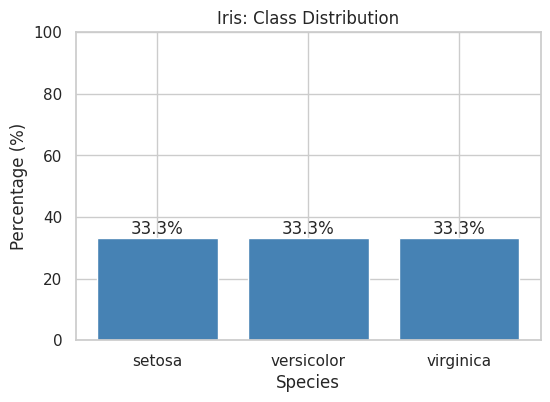

In [5]:
#### Iris 시각화

# 정답 열: species
# 정답(species) 별 클래스 비율
ratio = iris["species"].value_counts(normalize=True).sort_index() * 100
    # normalize=True -> 개수 대신 비율 계산
    # sort_index() 품종 이름(알파벳/가나다 순)을 기준으로 인덱스 정렬 : setosa, versicolor, virginica 순
    # 1. * 100 구한 비율(소수)에 100을 곱함 -> 백분율(%) 단위로 변환(ex 0.333 -> 33.3%)

display(ratio.rename("비율(%)").to_frame())

plt.figure(figsize=(6, 4))
bars = plt.bar(ratio.index, ratio.values, color="steelblue")

plt.bar_label(bars, fmt="%.1f%%")
plt.ylim(0, 100)
plt.xlabel("Species")
plt.ylabel("Percentage (%)")
plt.title("Iris: Class Distribution")
plt.show()

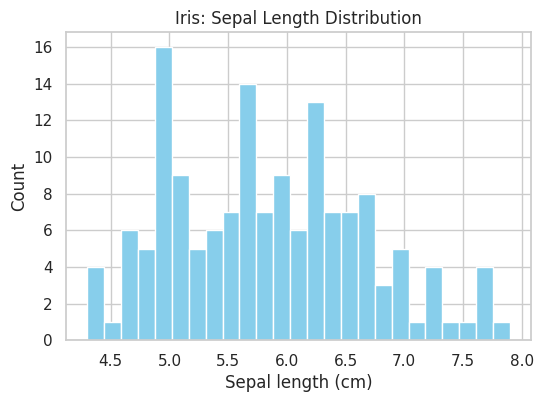

In [6]:
# Matplotlib 수치형 변수의 분포 — 히스토그램

plt.figure(figsize=(6, 4))

plt.hist(
    iris["sepal_length"].dropna(),
    bins=25,
    color="skyblue",
    edgecolor="white"
)

plt.xlabel("Sepal length (cm)")
plt.ylabel("Count")
plt.title("Iris: Sepal Length Distribution")
plt.show()

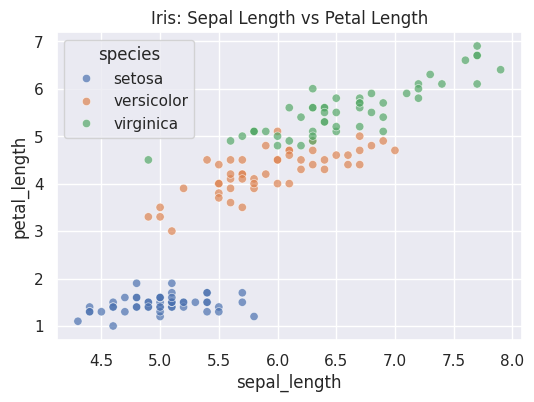

In [ ]:
# Seaborn 두 수치형 변수의 관계 — 산점도

plt.figure(figsize=(6, 4))

sns.scatterplot(
    data=iris,          # 사용할 데이터프레임
    x="sepal_length",   # 가로축: 수치형 변수
    y="petal_length",   # 세로축: 수치형 변수
    hue="species",      # 색상: 정답 클래스
    alpha=0.7
)

plt.title("Iris: Sepal Length vs Petal Length")
plt.show()

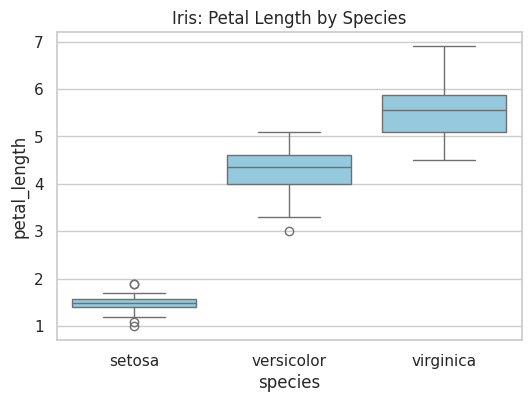

In [ ]:
# Seaborn 클래스별 수치 분포 — 상자그림

plt.figure(figsize=(6, 4))

sns.boxplot(
    data=iris,
    x="species",        # 가로축: 정답 클래스
    y="petal_length",   # 세로축: 비교할 수치형 변수
    color="skyblue"
)

plt.title("Iris: Petal Length by Species")
plt.show()

In [ ]:
### Titanic 에 적용
### iris와 다른 수정 포인트 확인 !!!

,비율(%)
survived,
0,61.616162
1,38.383838


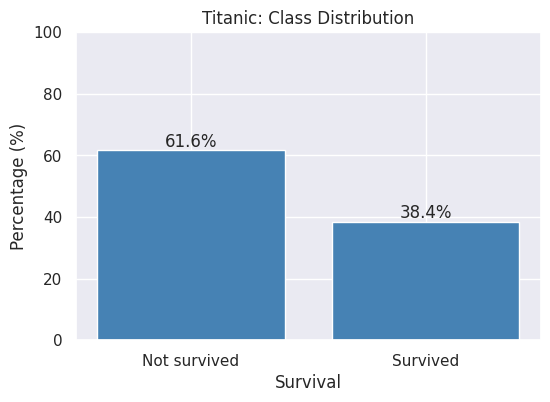

In [ ]:
# Matplotlib 정답 클래스 비율 — 막대그래프

### iris -> titanic
### 데이터(변수명)과 시각화 할 열 이름 수정

# 변경: iris -> titanic, species -> survived
# 생존 여부: 0 = 사망, 1 = 생존
ratio = titanic["survived"].value_counts(normalize=True).sort_index() * 100

display(ratio.rename("비율(%)").to_frame())

plt.figure(figsize=(6, 4))

# 숫자 클래스 정보를 문자 표현으로 변경 표시
bars = plt.bar(
    ["Not survived", "Survived"],  # X축 레이블, X축에 표시될 항목의 이름 지정 (순서대로 적용)
    ratio.reindex([0, 1]).values,  # Y축 값 (데이터 세팅)
                                   # reindex([0, 1]) 0과 1의 위치를 명확히 고정, 0을 첫번째..1을 두번째..
    # ratio.values,  # Y축 값 (데이터 세팅)
    color="steelblue" # 막대 색상
)

plt.bar_label(bars, fmt="%.1f%%")
plt.ylim(0, 100)
plt.xlabel("Survival")
plt.ylabel("Percentage (%)")
plt.title("Titanic: Class Distribution")
plt.show()

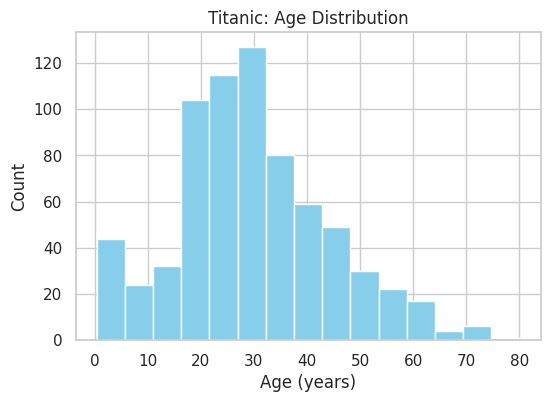

In [ ]:
# Matplotlib 수치형 변수의 분포 — 히스토그램

plt.figure(figsize=(6, 4))

# 변경: iris -> titanic, sepal_length -> age
# age의 결측치는 이 그래프에서만 제외
plt.hist(
    titanic["age"].dropna(),
    bins=15,
    color="skyblue",
    edgecolor="white"
)

# 데이터의 의미에 맞춰 축 이름과 제목도 변경
plt.xlabel("Age (years)")
plt.ylabel("Count")
plt.title("Titanic: Age Distribution")
plt.show()

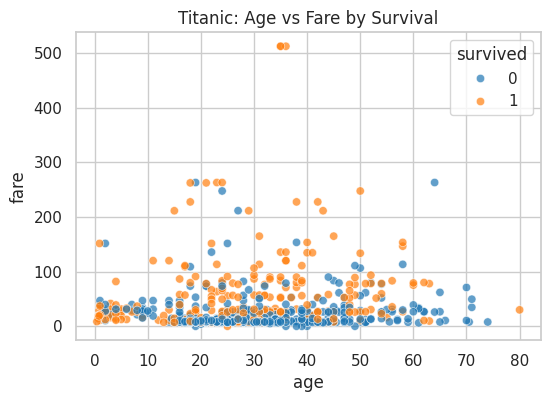

In [ ]:
# Seaborn 두 수치형 변수의 관계 — 산점도


# 산점도에 사용할 열에 결측치가 있는 행 제외
plot_data = titanic.dropna(subset=["age", "fare", "survived"])

plt.figure(figsize=(6, 4))

sns.scatterplot(
    data=plot_data,      # 변경: Titanic 데이터
    x="age",             # 변경: sepal_length -> age
    y="fare",            # 변경: petal_length -> fare
    hue="survived",       # 변경: species -> survived
    palette={0: "tab:blue", 1: "tab:orange"},
    alpha=0.7
)

plt.title("Titanic: Age vs Fare by Survival")
plt.show()

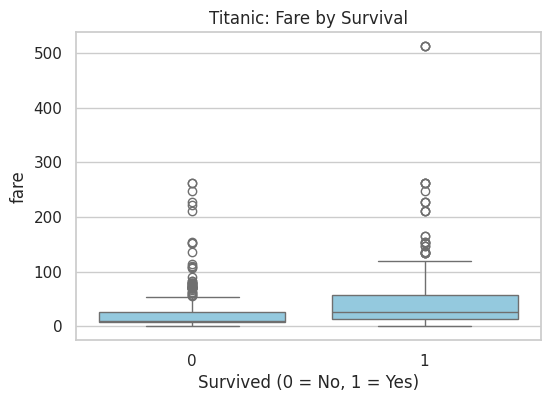

In [ ]:
# Seaborn 클래스별 수치 분포 — 상자그림

plot_data = titanic.dropna(subset=["survived", "fare"])

plt.figure(figsize=(6, 4))

sns.boxplot(
    data=plot_data,      # 변경: Iris -> Titanic
    x="survived",        # 변경: species -> survived
    y="fare",            # 변경: petal_length -> fare
    color="skyblue"
)

plt.xlabel("Survived (0 = No, 1 = Yes)")
plt.title("Titanic: Fare by Survival")
plt.show()

In [ ]:
## 기타 다양한 변수 조합으로 시각화 -> insight 도출

In [ ]:
## study data 탐색

In [ ]:
# 데이터 로드
df_study = pd.read_csv('/content/Study.공유.csv')

df_study.head()

,ID,survived,Month,AGE,StudyCnt_M1,StudyCntCnt_M2,StudyCntCnt_M3,StudyIndex_M1,StudyIndex_M2,StudyIndex_M3,Exam1_M1,Exam1_M2,Exam1_M3,Exam2_M1,Exam2_M2,Exam2_M3,Exam3_M1,Exam3_M2,Exam3_M3
0,1,1,39,52,19.0,14.0,20.0,45.0,41.0,57.0,92.76,96.43,93.75,84.96,85.25,92.28,67.42,76.65,95.88
1,2,1,5,49,31.0,22.0,27.0,72.0,73.0,81.0,96.65,95.45,95.56,105.90,109.56,111.27,102.57,94.68,105.88
2,3,1,1,19,2.0,NaN,NaN,41.0,NaN,NaN,100.00,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,4,1,8,17,31.0,7.0,NaN,88.0,63.0,NaN,92.14,100.00,NaN,112.28,105.98,NaN,119.20,NaN,NaN
4,5,1,7,17,42.0,47.0,41.0,32.0,33.0,33.0,62.78,71.20,71.90,NaN,NaN,NaN,NaN,NaN,NaN
